## MLP - NoteBook

In [269]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib

Using matplotlib backend: module://matplotlib_inline.backend_inline


In [270]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [271]:
len(words)

32033

In [ ]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [273]:
block_size = 3
X, Y = [], []

for w in words:
  
  # print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    # print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [274]:

def build_dataset(words):  
    block_size = 3
    X, Y = [], []
  
    for w in words:
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [275]:
X.shape, X.dtype

(torch.Size([228146, 3]), torch.int64)

In [276]:
X

tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        ...,
        [26, 26, 25],
        [26, 25, 26],
        [25, 26, 24]])

In [277]:
C = torch.randn((27, 2))

In [278]:
# F.one_hot(torch.tensor(5), num_classes=27).float() @ C
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [279]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [280]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

# torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape
# torch.cat(torch.unbind(emb, 1), 1).shape

In [281]:
h

tensor([[ 0.1262, -0.9708, -0.9942,  ..., -0.3415,  0.6868,  0.9811],
        [-0.5231, -0.6046, -0.9698,  ...,  0.9851,  0.7995,  0.9005],
        [-0.9971, -0.1158, -0.6737,  ...,  0.9603,  0.7536, -0.4268],
        ...,
        [ 0.9304, -0.9835,  0.9961,  ...,  0.9781, -0.6032, -0.9183],
        [ 0.9793, -0.7423,  0.9958,  ...,  0.9997, -0.4177, -0.2114],
        [ 0.8706, -0.3239,  0.8982,  ...,  0.9997, -0.9962, -0.9267]])

In [282]:
h.shape

torch.Size([228146, 100])

In [283]:
W2 = torch.randn(100, 27)
b2 = torch.randn(27)

In [284]:
logits = h @ W2 + b2

In [285]:
logits.shape

torch.Size([228146, 27])

In [286]:
counts = logits.exp()

In [287]:
prob = counts / counts.sum(1, keepdim=True)

In [288]:
prob.shape

torch.Size([228146, 27])

In [289]:
# loss = -prob[torch.arange(32), Y].log().mean()
# loss

In [290]:
Y

tensor([ 5, 13, 13,  ..., 26, 24,  0])

---- made respectable -----

In [291]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [292]:
sum(p.nelement() for p in parameters)

11897

In [293]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [294]:
sum(p.nelement() for p in parameters)

11897

In [295]:
for p in parameters:
    p.requires_grad=True

In [296]:
lre = torch.linspace(-3 , 0 , 1000)
lrs = 10**lre

In [297]:
lri = []
lossi = []
stepi = []

In [ ]:
for i in range(200000):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32, ))

    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    # print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    # lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())
# print(loss.item())

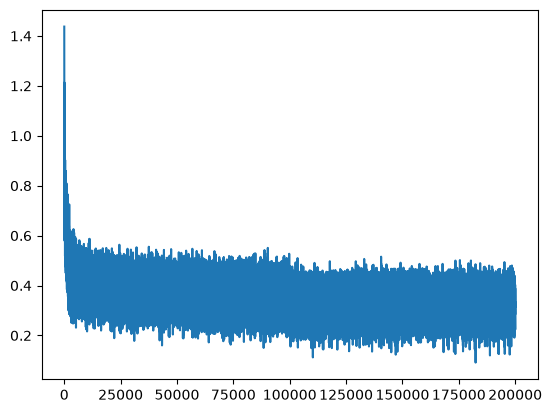

In [299]:
plt.plot(stepi, lossi)

In [300]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1309, grad_fn=<NllLossBackward0>)

In [301]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1688, grad_fn=<NllLossBackward0>)

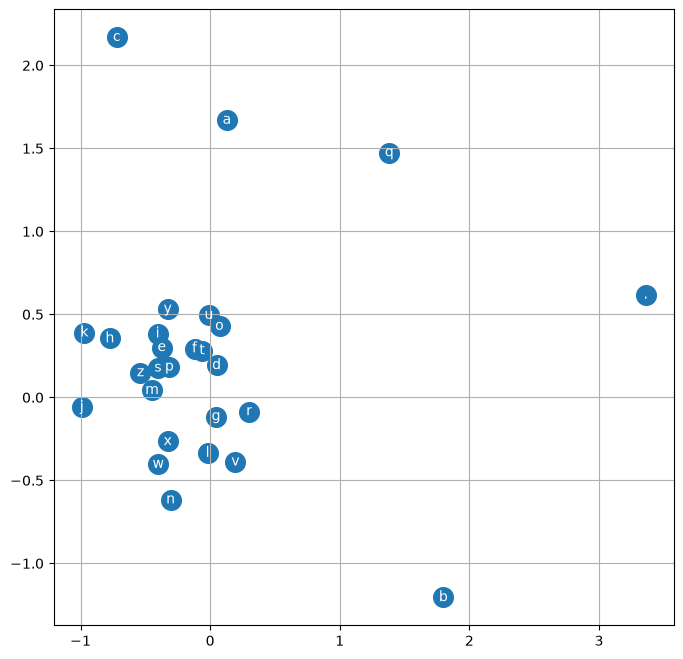

In [302]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [303]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [ ]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
  out = []
  context = [0] * block_size
  while True:
    emb = C[torch.tensor([context])]
    h = torch.tanh(emb.view(1, -1) @ W1 + b1)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break
    
  print(''.join(itos[i] for i in out))

carmahfati.
hari.
kemyli.
taty.
sachos.
emmahiel.
den.
rha.
areen.
ner.
ara.
chaiir.
asleigh.
ham.
prin.
quinn.
shorlei.
jadiq.
wazelo.
dearysia.
